Make the code that would create a map that assigns the name of the county in the centroid using the methods presented in class and with no use of Ai or internet searches.

This extra credit is only for the students that were present in today's class. 

In [8]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

<Axes: >

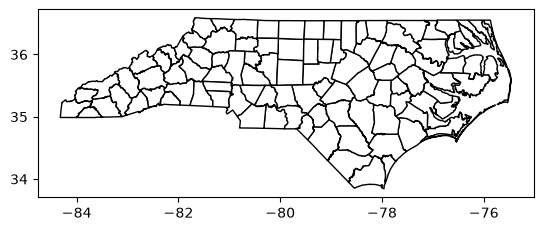

In [9]:
# Following in-class example
# getting the US census data

url_0 = "https://www2.census.gov/geo/tiger/GENZ2024/shp/" # url for census tiger data 
url_county = "cb_2024_us_county_500k.zip" # county level
url_state = "cb_2024_us_state_500k.zip" # state level 


## Code for county level data 

counties = gpd.read_file(url_0+url_county)
nc_counties = counties.loc[counties["STATEFP"] == "37"].copy()
nc_counties.plot(edgecolor="black", facecolor="white")

<Axes: >

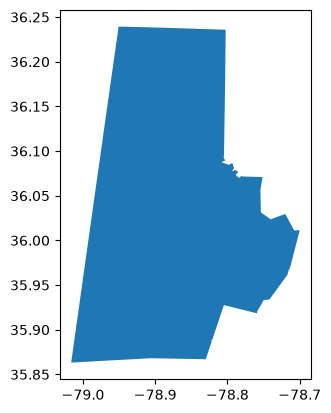

In [10]:
# Selecting only Durham county 
durham = nc_counties[nc_counties["NAME"] == "Durham"]
durham.plot()

In [11]:
durham

,STATEFP,COUNTYFP,COUNTYNS,GEOIDFQ,GEOID,NAME,NAMELSAD,STUSPS,STATE_NAME,LSAD,ALAND,AWATER,geometry
1931,37,063,01008550,0500000US37063,37063,Durham,Durham County,NC,North Carolina,06,744748241,26712251,"POLYGON ((-79.01207 35.88753, -79.01158 35.890..."


In [18]:
nc_counties

,STATEFP,COUNTYFP,COUNTYNS,GEOIDFQ,GEOID,NAME,NAMELSAD,STUSPS,STATE_NAME,LSAD,ALAND,AWATER,geometry
90,37,047,01026339,0500000US37047,37047,Columbus,Columbus County,NC,North Carolina,06,2429920494,43711694,"POLYGON ((-79.07124 34.2993, -79.06894 34.3010..."
91,37,039,01008545,0500000US37039,37039,Cherokee,Cherokee County,NC,North Carolina,06,1179842036,28813680,"POLYGON ((-84.31749 35.02184, -84.31748 35.021..."
92,37,149,01008579,0500000US37149,37149,Polk,Polk County,NC,North Carolina,06,615606325,1964035,"POLYGON ((-82.35925 35.22993, -82.35924 35.230..."
93,37,009,01008535,0500000US37009,37009,Ashe,Ashe County,NC,North Carolina,06,1104023356,8058446,"POLYGON ((-81.74065 36.41314, -81.7373 36.4135..."
94,37,055,01026133,0500000US37055,37055,Dare,Dare County,NC,North Carolina,06,992558552,3000513281,"MULTIPOLYGON (((-75.72681 35.93584, -75.71827 ..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3001,37,069,01008553,0500000US37069,37069,Franklin,Franklin County,NC,North Carolina,06,1273761678,7173998,"POLYGON ((-78.54551 36.0567, -78.54493 36.0772..."
3012,37,097,01008565,0500000US37097,37097,Iredell,Iredell County,NC,North Carolina,06,1487784939,59453223,"POLYGON ((-81.10951 35.77659, -81.10656 35.778..."
3045,37,187,01026331,0500000US37187,37187,Washington,Washington County,NC,North Carolina,06,897456201,195282199,"POLYGON ((-76.84726 35.71998, -76.84362 35.722..."
3087,37,071,01008554,0500000US37071,37071,Gaston,Gaston County,NC,North Carolina,06,921389625,20549066,"POLYGON ((-81.4556 35.41981, -81.40985 35.4182..."


/var/folders/k4/0d_fkbsj5gs7vl1cm28c39kr0000gn/T/ipykernel_89790/1329215644.py:1: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  nc_counties['centroid'] = nc_counties.geometry.centroid


<Axes: >

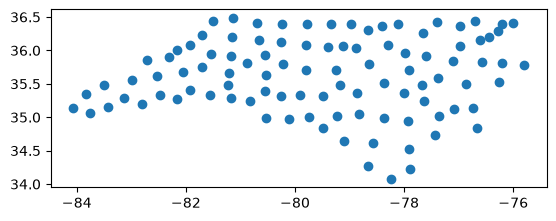

In [101]:
nc_counties['centroid'] = nc_counties.geometry.centroid
nc_counties.plot()

In [94]:
# Min-Max Normalization 
w_max = nc_counties["ALAND"].max()
w_min = nc_counties["ALAND"].min()
w_range = w_max - w_min

nc_counties['normalized'] = (nc_counties['ALAND']-w_min) / w_range
max(nc_counties['normalized'])

1.0

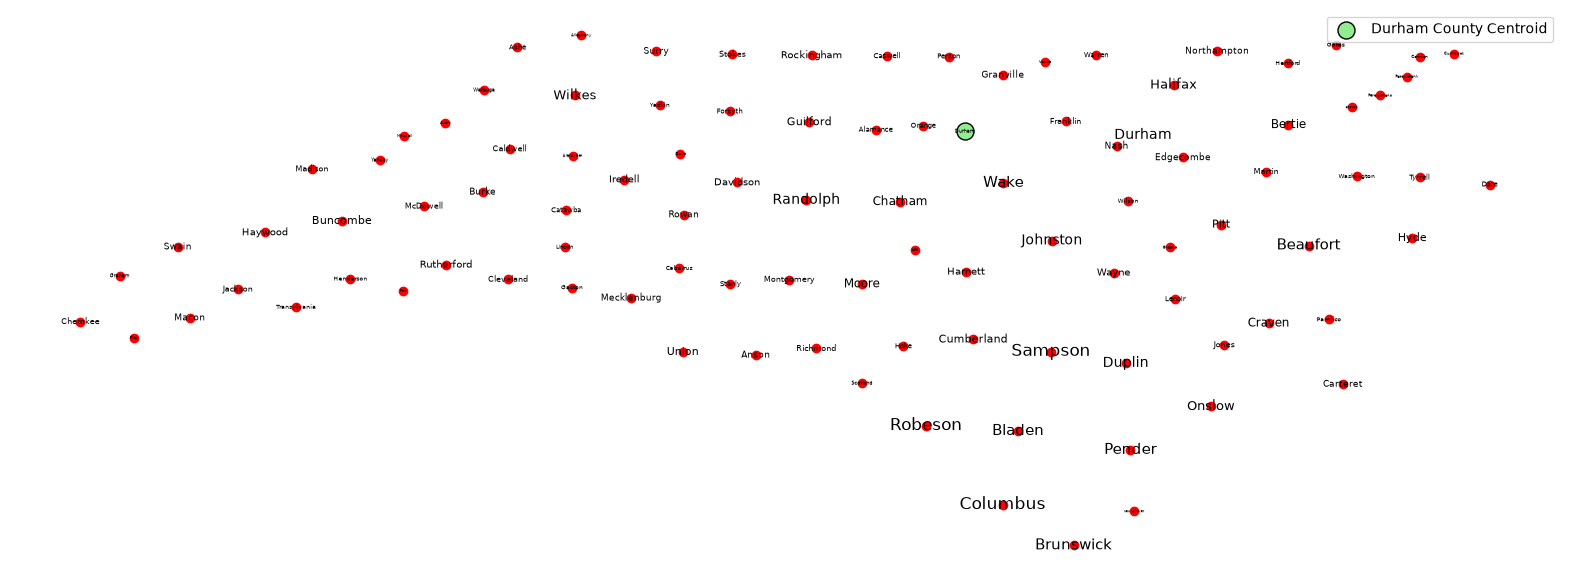

In [104]:
# setting up plot
fig, ax = plt.subplots(figsize=(20, 20))

# based on the info provided by Javier:
ncc = nc_counties
x = int(ncc[ncc["NAME"]== "Durham"]['geometry'].x.iloc[0])

y = int(ncc[ncc["NAME"]== "Durham"]['geometry'].y.iloc[0])

# Now plotting 
nc_counties.plot(ax=ax, color="red")
durham.plot(ax=ax, color='lightgreen', markersize=150, edgecolor='black', label='Durham County Centroid') # to stand out 


ax.text(x,y, 'Durham', color = 'black')


for index, row in nc_counties.iterrows():
    center = row.geometry.centroid

    ax.text(
        center.x,
        center.y,
        row["NAME"],
        # fontsize=row['ALAND']/100000000,
        fontsize=(row['normalized']*10)+2,
        ha="center",
        va="center"
    )
ax.legend(loc='upper right', fontsize=10)

ax.set_axis_off()
plt.show()